## VOLTA

## 1. Setup & Load  


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot settings (shared by all plots in this notebook)
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["font.size"] = 10

energy = pd.read_csv("../data/raw/energy_dataset.csv")
weather = pd.read_csv("../data/raw/weather_features.csv")

print("Energy:", energy.shape)
print("Weather:", weather.shape)

Energy: (35064, 29)
Weather: (178396, 17)


## Check Columns & Structure

In [3]:
display(energy.head())
display(weather.head())

,time,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
0,2015-01-01 00:00:00+01:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
1,2015-01-01 01:00:00+01:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2,2015-01-01 02:00:00+01:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48
3,2015-01-01 03:00:00+01:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,...,191.0,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32
4,2015-01-01 04:00:00+01:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,...,189.0,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04


,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
0,2015-01-01 00:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
1,2015-01-01 01:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
2,2015-01-01 02:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
3,2015-01-01 03:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
4,2015-01-01 04:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n


In [4]:
print("ENERGY COLUMNS:")
print(energy.columns.tolist())

print("\nWEATHER COLUMNS:")
print(weather.columns.tolist())


ENERGY COLUMNS:
['time', 'generation biomass', 'generation fossil brown coal/lignite', 'generation fossil coal-derived gas', 'generation fossil gas', 'generation fossil hard coal', 'generation fossil oil', 'generation fossil oil shale', 'generation fossil peat', 'generation geothermal', 'generation hydro pumped storage aggregated', 'generation hydro pumped storage consumption', 'generation hydro run-of-river and poundage', 'generation hydro water reservoir', 'generation marine', 'generation nuclear', 'generation other', 'generation other renewable', 'generation solar', 'generation waste', 'generation wind offshore', 'generation wind onshore', 'forecast solar day ahead', 'forecast wind offshore eday ahead', 'forecast wind onshore day ahead', 'total load forecast', 'total load actual', 'price day ahead', 'price actual']

WEATHER COLUMNS:
['dt_iso', 'city_name', 'temp', 'temp_min', 'temp_max', 'pressure', 'humidity', 'wind_speed', 'wind_deg', 'rain_1h', 'rain_3h', 'snow_3h', 'clouds_all',

In [5]:
print("ENERGY INFO")
energy.info()
print("\nWEATHER INFO")
weather.info()

ENERGY INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 29 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   time                                         35064 non-null  object 
 1   generation biomass                           35045 non-null  float64
 2   generation fossil brown coal/lignite         35046 non-null  float64
 3   generation fossil coal-derived gas           35046 non-null  float64
 4   generation fossil gas                        35046 non-null  float64
 5   generation fossil hard coal                  35046 non-null  float64
 6   generation fossil oil                        35045 non-null  float64
 7   generation fossil oil shale                  35046 non-null  float64
 8   generation fossil peat                       35046 non-null  float64
 9   generation geothermal                        35046 non-null 

## Convert Timestamps



In [6]:
# Keep the original data unchanged
energy_raw = energy.copy()
weather_raw = weather.copy()

# Convert timestamps to datetime
energy["time"] = pd.to_datetime(energy["time"], utc=True)
weather["dt_iso"] = pd.to_datetime(weather["dt_iso"], utc=True)

# Check time ranges
print("Energy start:", energy["time"].min())
print("Energy end:", energy["time"].max())

print("Weather start:", weather["dt_iso"].min())
print("Weather end:", weather["dt_iso"].max())

# Check data types
print("Energy time dtype:", energy["time"].dtype)
print("Weather time dtype:", weather["dt_iso"].dtype)

Energy start: 2014-12-31 23:00:00+00:00
Energy end: 2018-12-31 22:00:00+00:00
Weather start: 2014-12-31 23:00:00+00:00
Weather end: 2018-12-31 22:00:00+00:00
Energy time dtype: datetime64[ns, UTC]
Weather time dtype: datetime64[ns, UTC]


## Sort & Set Index


In [7]:
energy = energy.sort_values("time")
energy = energy.set_index("time")
energy.head(3)

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
time,,,,,,,,,,,,,,,,,,,,,
2014-12-31 23:00:00+00:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,NaN,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
2015-01-01 00:00:00+00:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,NaN,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2015-01-01 01:00:00+00:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,NaN,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48


## Check Energy Timestamps


In [8]:
print("Sorted:", energy.index.is_monotonic_increasing)
print("Duplicate timestamps:", energy.index.duplicated().sum())
print(energy.index.to_series().diff().value_counts())

Sorted: True
Duplicate timestamps: 0
time
0 days 01:00:00    35063
Name: count, dtype: int64


## Check Weather Cities & Duplicates

In [9]:
print(weather["city_name"].value_counts())
print("Duplicate (time, city):", weather.duplicated(subset=["dt_iso", "city_name"]).sum())

city_name
Madrid        36267
Bilbao        35951
Seville       35557
 Barcelona    35476
Valencia      35145
Name: count, dtype: int64
Duplicate (time, city): 3076


## Inspect Weather Duplicates

In [10]:
dups = weather[weather.duplicated(subset=["dt_iso", "city_name"], keep=False)]
dups = dups.sort_values(["city_name", "dt_iso"])
dups.head(6)

,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
109256,2015-03-20 20:00:00+00:00,Barcelona,286.81,282.59,291.48,1013,76,12,50,0.3,0.0,0.0,40,500,rain,light rain,10n
109257,2015-03-20 20:00:00+00:00,Barcelona,286.81,282.59,291.48,1013,76,12,50,0.3,0.0,0.0,40,301,drizzle,drizzle,09n
111170,2015-06-08 13:00:00+00:00,Barcelona,299.47,291.48,304.82,1017,57,3,180,12.0,0.0,0.0,20,503,rain,very heavy rain,10d
111171,2015-06-08 13:00:00+00:00,Barcelona,299.47,291.48,304.82,1017,57,3,180,12.0,0.0,0.0,20,211,thunderstorm,thunderstorm,11d
111172,2015-06-08 14:00:00+00:00,Barcelona,297.59,292.04,300.37,1017,54,2,170,3.0,0.0,0.0,20,502,rain,heavy intensity rain,10d
111173,2015-06-08 14:00:00+00:00,Barcelona,297.59,292.04,300.37,1017,54,2,170,3.0,0.0,0.0,20,211,thunderstorm,thunderstorm,11d


In [11]:
num_cols = ["temp","temp_min","temp_max","pressure","humidity",
            "wind_speed","wind_deg","rain_1h","rain_3h","snow_3h","clouds_all"]
dup_rows = weather[weather.duplicated(subset=["dt_iso","city_name"], keep=False)]
diff = dup_rows.groupby(["dt_iso","city_name"])[num_cols].nunique().max(axis=1)
print("Duplicate pairs with different numeric values:", (diff > 1).sum())

Duplicate pairs with different numeric values: 0


## Key Columns

| Column | Meaning | Unit |
|---|---|---|
| time / dt_iso | Timestamp (converted to UTC) | UTC hour |
| generation solar / wind onshore / wind offshore | Actual electricity generated | MW |
| generation fossil gas / hard coal / brown coal-lignite / oil | Actual electricity generated | MW |
| total load actual | Actual electricity demand | MW |
| total load forecast | Official day-ahead demand forecast | MW |
| forecast solar / wind onshore day ahead | Official day-ahead generation forecasts | MW |
| price actual | Actual electricity price | EUR/MWh |
| price day ahead | Day-ahead electricity market price | EUR/MWh |
| temp, temp_min, temp_max | Temperature (per city) | Kelvin |
| pressure | Air pressure | hPa |
| humidity, clouds_all | Humidity, cloud cover | % |
| wind_speed, wind_deg | Wind speed, direction | m/s, degrees |
| rain_1h, rain_3h, snow_3h | Precipitation | mm |

Units are the usual ones for this dataset and should be confirmed against the dataset description.

## Track A — Key Findings

- Energy data contains 35,064 hourly records, from 2014-12-31 23:00 UTC to 2018-12-31 22:00 UTC.
- Energy timestamps are sorted, with no duplicate or missing hours within the recorded period.
- Weather data covers five cities and approximately the same period as the energy data.
- Two Energy columns are completely empty: `generation hydro pumped storage aggregated` and `forecast wind offshore day ahead`.
- `total load actual` has 36 missing values (35,028 non-null out of 35,064).
- Weather has no missing values reported by `info()`.
- Weather has 3,076 duplicate (hour, city) entries.
- Initial inspection shows that some duplicate weather records have identical numerical measurements but different weather descriptions.
- Further checks are needed to confirm whether numerical measurements differ in other duplicated records.
- No duplicates or missing values have been removed or filled yet.

# Track B: Time Series Data Visualization
**Author:** Mohammed Ghannam Alyami
**Project:** VOLTA — Energy Pressure Forecasting
**Task:** Exploratory Data Analysis (EDA) & Trend Analysis

Objective: analyze trends, seasonality, daily/weekly patterns and anomalies across the four main targets:
1. Electricity Demand (`total load actual`)
2. Price (`price actual`)
3. Renewable Generation
4. Fossil Generation

In [11]:
# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Shared colors and clean chart style for all plots below
MAIN, LIGHT, LOW, HIGH = '#5B4BDB', '#CFC9F7', '#2CA58D', '#E5446D'

def clean_style(axes):
    """Light horizontal grid only, no top/right borders."""
    for ax in np.atleast_1d(axes):
        ax.grid(False)
        ax.grid(axis='y', alpha=0.3)
        ax.spines[['top', 'right']].set_visible(False)

# Track A already loaded, converted and sorted the data: reuse it
df = energy.copy()

# 2. Correct Renewable Generation Columns (Actual generation only)
# NOTE: biomass moved here from fossil (it is classified as renewable)
renewable_cols = [
    'generation hydro run-of-river and poundage',
    'generation hydro water reservoir',
    'generation solar',
    'generation wind onshore',
    'generation biomass'
]

# 3. Correct Fossil Generation Columns (Actual generation only)
fossil_cols = [
    'generation fossil brown coal/lignite',
    'generation fossil gas',
    'generation fossil hard coal',
    'generation fossil oil'
]

# Calculate exact total generation for Renewable and Fossil
df['renewable_total'] = df[renewable_cols].sum(axis=1)
df['fossil_total'] = df[fossil_cols].sum(axis=1)

print("Data successfully loaded!")
print(f"Time Period: {df.index.min()} to {df.index.max()}")
print(f"Renewable actual columns count: {len(renewable_cols)}")
print(f"Fossil actual columns count: {len(fossil_cols)}")

Data successfully loaded!
Time Period: 2014-12-31 23:00:00+00:00 to 2018-12-31 22:00:00+00:00
Renewable actual columns count: 5
Fossil actual columns count: 4


## 1. Renewable vs Fossil Generation Trends (2015 – 2018)
*Question:* How do Renewable and Fossil energy generations compare over time, and do they show complementary seasonal patterns?

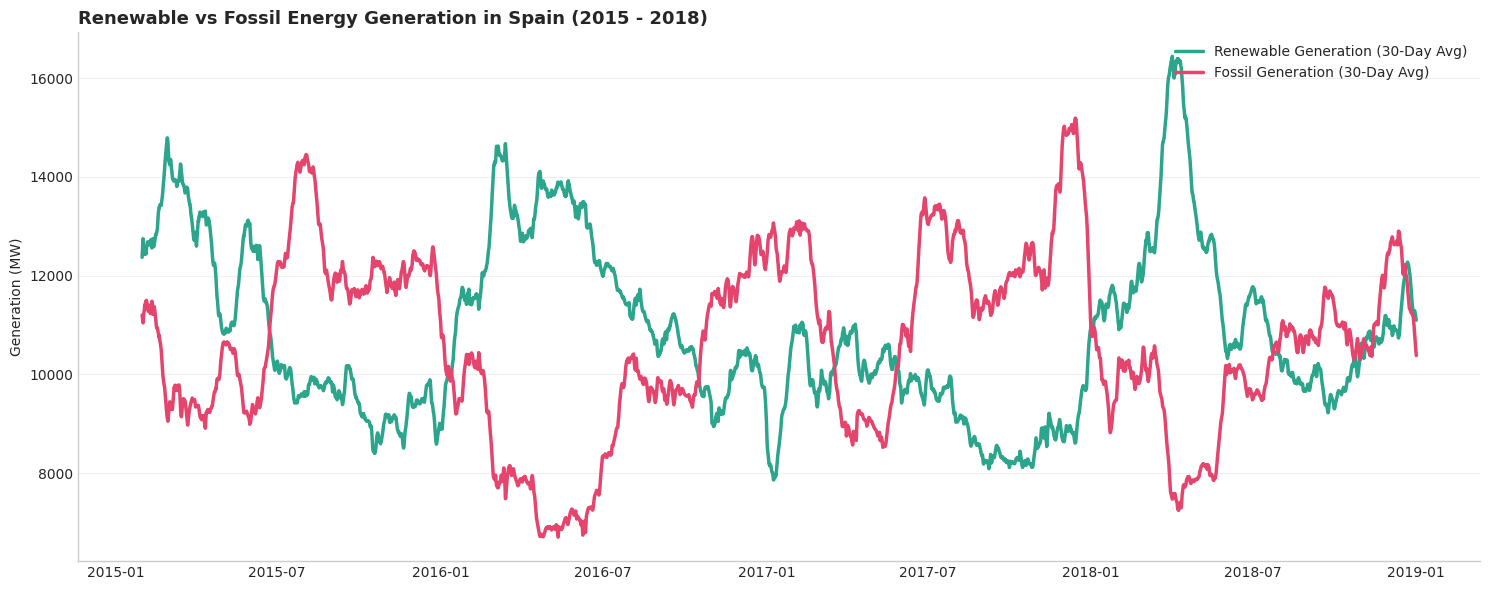

In [12]:
# Plot Renewable vs Fossil Generation over time with 30-day moving average
fig, ax = plt.subplots(figsize=(15, 6))

# 30-day Moving Averages for clean visual comparison
ax.plot(df['renewable_total'].rolling(window=24*30).mean(), color=LOW, linewidth=2.5, label='Renewable Generation (30-Day Avg)')
ax.plot(df['fossil_total'].rolling(window=24*30).mean(), color=HIGH, linewidth=2.5, label='Fossil Generation (30-Day Avg)')

ax.set_title('Renewable vs Fossil Energy Generation in Spain (2015 - 2018)', fontsize=13, fontweight='bold', loc='left')
ax.set_ylabel('Generation (MW)')
ax.legend(loc='upper right', frameon=False)
clean_style(ax)

plt.tight_layout()
plt.savefig('renewable_vs_fossil_trend.png', dpi=300)
plt.show()

## 2. Sudden Changes & Unusual Events (Spikes & Anomalies)
*Question:* Are there extreme price spikes or sudden anomalies in electricity demand that could affect model evaluation?

Price Spike Threshold (99th percentile): 87.46 EUR/MWh
Total Hourly Spikes Detected: 351


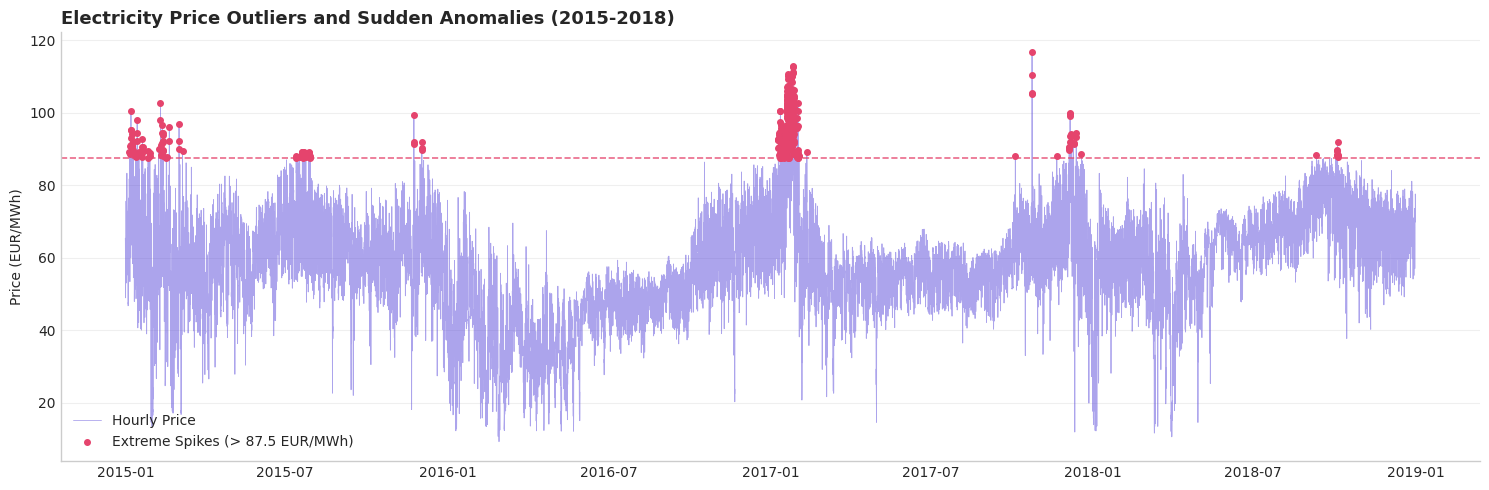

In [14]:
# Detect extreme price spikes (e.g., prices > 90th percentile or above 80 EUR/MWh)
price_threshold = df['price actual'].quantile(0.99)
spikes = df[df['price actual'] > price_threshold]

print(f"Price Spike Threshold (99th percentile): {price_threshold:.2f} EUR/MWh")
print(f"Total Hourly Spikes Detected: {len(spikes)}")

# Plotting Price Spikes and Extreme Anomalies
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df.index, df['price actual'], color=MAIN, alpha=0.5, linewidth=0.6, label='Hourly Price')
ax.axhline(price_threshold, color=HIGH, linestyle='--', linewidth=1.2, alpha=0.8)
ax.scatter(spikes.index, spikes['price actual'], color=HIGH, s=16, zorder=5, label=f'Extreme Spikes (> {price_threshold:.1f} EUR/MWh)')

ax.set_title('Electricity Price Outliers and Sudden Anomalies (2015-2018)', fontsize=13, fontweight='bold', loc='left')
ax.set_ylabel('Price (EUR/MWh)')
ax.legend(loc='lower left', frameon=False)
clean_style(ax)

plt.tight_layout()
plt.savefig('unusual_events_spikes.png', dpi=300)
plt.show()

## 3. Continuity Analysis: Missing Periods & Timestamp Gaps
*Question:* Are there missing hourly records or changes in the measurement time sequence across the 4-year period?

Total Expected Hours: 35064
Total Actual Rows in Dataset: 35064
Number of Missing Hourly Timestamps: 0


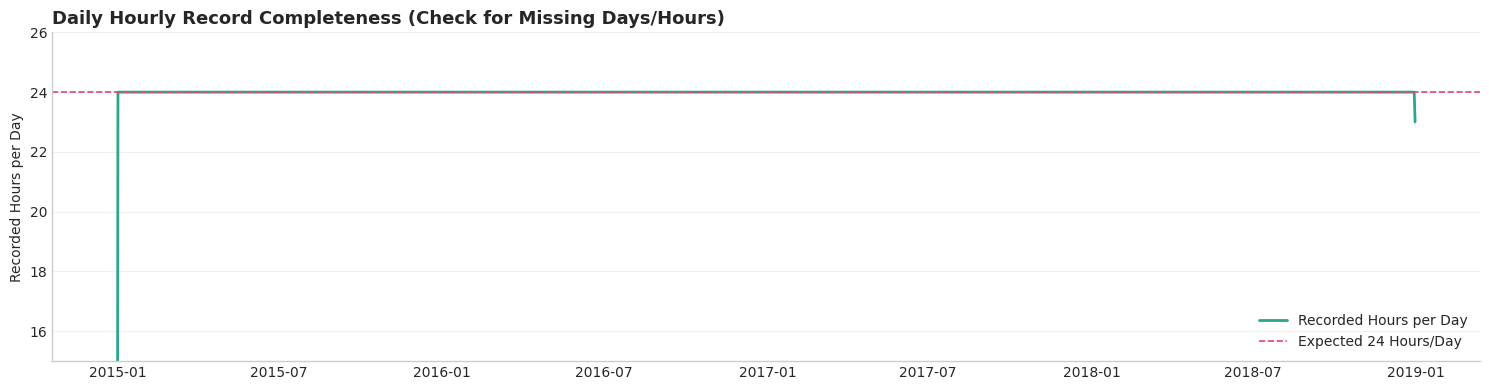

In [15]:
# Generate a complete hourly range from start date to end date
expected_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='h')

# Identify missing hourly timestamps
missing_timestamps = expected_range.difference(df.index)

print(f"Total Expected Hours: {len(expected_range)}")
print(f"Total Actual Rows in Dataset: {len(df)}")
print(f"Number of Missing Hourly Timestamps: {len(missing_timestamps)}")

# Plot hourly data density over time to inspect measurement consistency
hourly_counts = df.resample('D')['price actual'].count()

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(hourly_counts.index, hourly_counts.values, color=LOW, linewidth=2, label='Recorded Hours per Day')
ax.axhline(24, color=HIGH, linestyle='--', linewidth=1.2, label='Expected 24 Hours/Day')

ax.set_title('Daily Hourly Record Completeness (Check for Missing Days/Hours)', fontsize=13, fontweight='bold', loc='left')
ax.set_ylabel('Recorded Hours per Day')
ax.set_ylim(15, 26)
ax.legend(loc='lower right', frameon=False)
clean_style(ax)

plt.tight_layout()
plt.savefig('missing_periods_check.png', dpi=300)
plt.show()

## 4. Daily & Weekly Price Patterns
*Question:* Does the electricity price (`price actual`) follow a daily and weekly pattern? Which hours are cheapest and most expensive?

We use Spain's local time (Europe/Madrid), because people and businesses follow the local clock. This is also the calendar used for the `is_weekend` model feature.

Cheapest hour: 4:00 (47.4 EUR/MWh)
Most expensive hour: 21:00 (65.6 EUR/MWh)
Daily range: 18.1 EUR/MWh
Weekday average: 59.8 EUR/MWh | Weekend average: 53.1 EUR/MWh
Weekend is 11.2% cheaper than weekdays


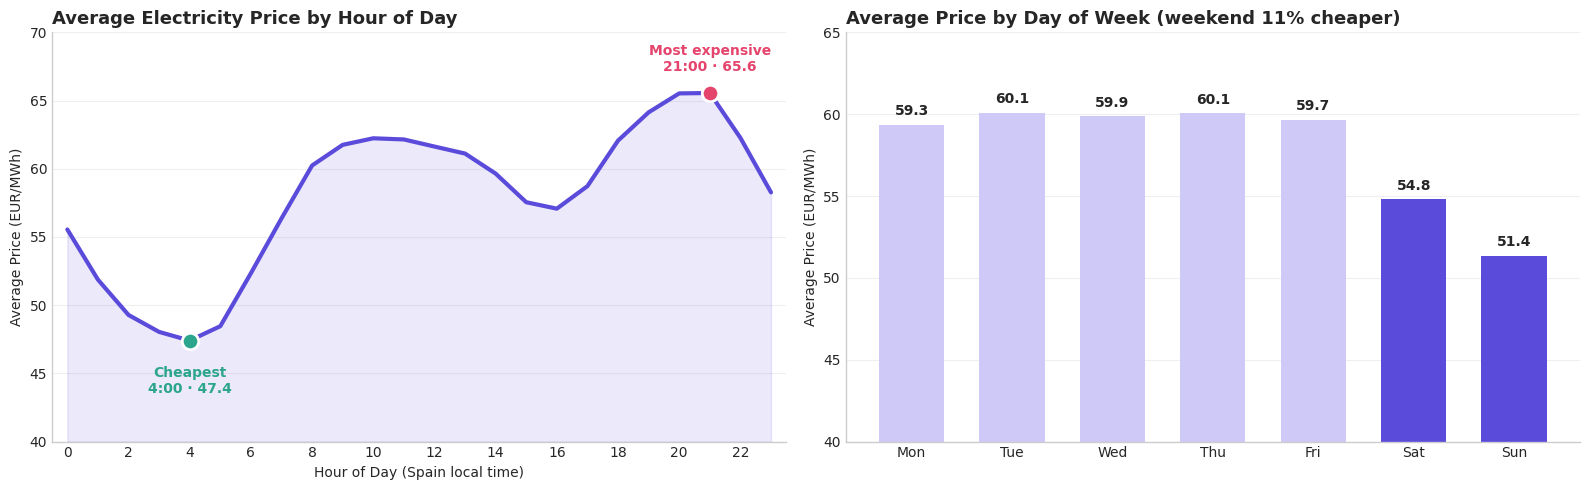

In [16]:
# Convert timestamps to Spain's local time
local_time = df.index.tz_convert('Europe/Madrid')

# Order days chronologically starting from Monday
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Average price by hour of day and by day of week
avg_price_hour = df.groupby(local_time.hour)['price actual'].mean()
avg_price_day = df.groupby(local_time.day_name())['price actual'].mean().reindex(days_order)

# Weekday vs weekend
is_weekend = local_time.dayofweek >= 5
weekday_price = df.loc[~is_weekend, 'price actual'].mean()
weekend_price = df.loc[is_weekend, 'price actual'].mean()

print(f"Cheapest hour: {avg_price_hour.idxmin()}:00 ({avg_price_hour.min():.1f} EUR/MWh)")
print(f"Most expensive hour: {avg_price_hour.idxmax()}:00 ({avg_price_hour.max():.1f} EUR/MWh)")
print(f"Daily range: {avg_price_hour.max() - avg_price_hour.min():.1f} EUR/MWh")
print(f"Weekday average: {weekday_price:.1f} EUR/MWh | Weekend average: {weekend_price:.1f} EUR/MWh")
print(f"Weekend is {(1 - weekend_price / weekday_price) * 100:.1f}% cheaper than weekdays")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Line Chart: Average Price by Hour of Day
ax = axes[0]
ax.plot(avg_price_hour.index, avg_price_hour.values, color=MAIN, linewidth=3)
ax.fill_between(avg_price_hour.index, avg_price_hour.values, 40, color=MAIN, alpha=0.12)
for hour, color, label, offset in [(avg_price_hour.idxmin(), LOW, 'Cheapest', -38),
                                   (avg_price_hour.idxmax(), HIGH, 'Most expensive', 16)]:
    ax.scatter(hour, avg_price_hour[hour], color=color, s=140, zorder=5, edgecolor='white', linewidth=2)
    ax.annotate(f'{label}\n{hour}:00 · {avg_price_hour[hour]:.1f}', (hour, avg_price_hour[hour]),
                xytext=(0, offset), textcoords='offset points', ha='center', color=color, fontweight='bold')
ax.set_title('Average Electricity Price by Hour of Day', fontsize=13, fontweight='bold', loc='left')
ax.set_xlabel('Hour of Day (Spain local time)')
ax.set_ylabel('Average Price (EUR/MWh)')
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(40, 70)

# 2. Bar Chart: Average Price by Day of Week (weekend highlighted)
ax = axes[1]
bars = ax.bar(avg_price_day.index.str[:3], avg_price_day.values, color=[LIGHT]*5 + [MAIN]*2, width=0.65)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.4, f'{yval:.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title(f'Average Price by Day of Week (weekend {(1 - weekend_price / weekday_price) * 100:.0f}% cheaper)',
             fontsize=13, fontweight='bold', loc='left')
ax.set_ylabel('Average Price (EUR/MWh)')
ax.set_ylim(40, 65)

clean_style(axes)

plt.tight_layout()
plt.savefig('price_patterns.png', dpi=300)
plt.show()

## 5. Price Level Over the Years
*Question:* Does the average price stay the same over time?

We use UTC years here, the same as the data split. The single 2014 hour (2014-12-31 23:00 UTC) is left out.

Train (2015-2016): 54.4 EUR/MWh
Validation (2017): 59.3 EUR/MWh
Test (2018): 63.4 EUR/MWh
Test is 16.6% higher than Train


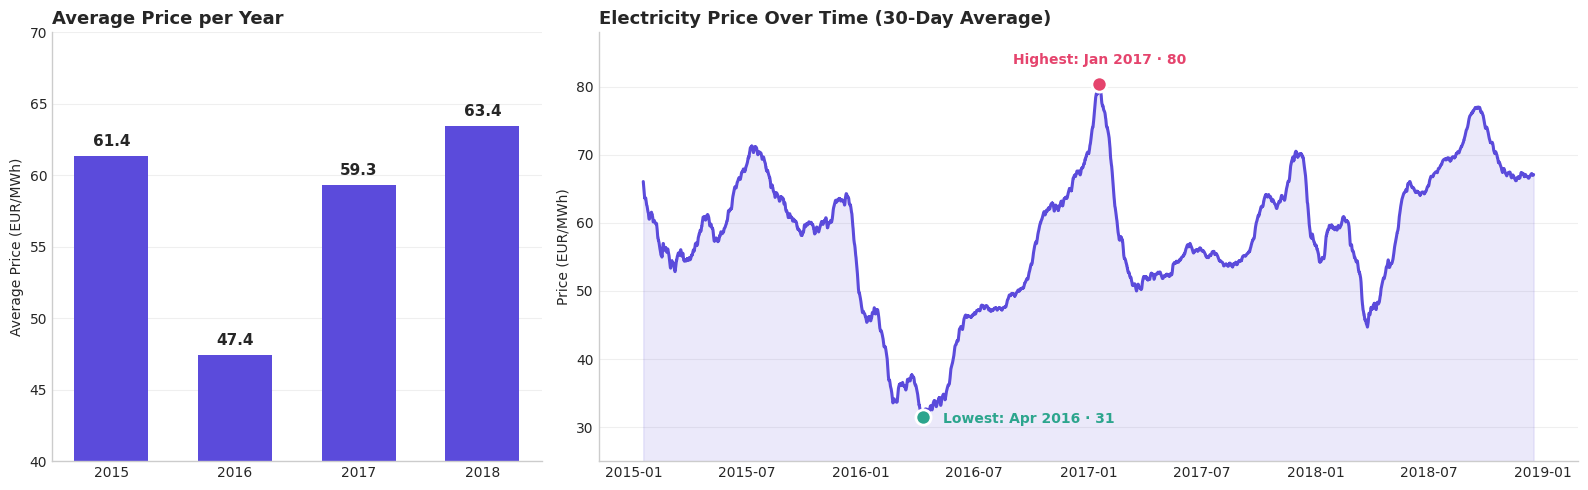

In [17]:
# Average price per year (UTC, same as the data split)
price_by_year = df.loc['2015':'2018', 'price actual']
avg_price_year = price_by_year.groupby(price_by_year.index.year).mean()

# Average price per split period
splits = {
    'Train (2015-2016)': df.loc['2015':'2016', 'price actual'].mean(),
    'Validation (2017)': df.loc['2017', 'price actual'].mean(),
    'Test (2018)': df.loc['2018', 'price actual'].mean(),
}
for name, value in splits.items():
    print(f"{name}: {value:.1f} EUR/MWh")
print(f"Test is {(splits['Test (2018)'] / splits['Train (2015-2016)'] - 1) * 100:.1f}% higher than Train")

# 30-day average price and its lowest / highest points
price_30d = df['price actual'].rolling(window=24*30, center=True).mean()   # centered: each point = 15 days before + 15 days after

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 2]})

# 1. Bar Chart: Average Price per Year
ax = axes[0]
bars = ax.bar(avg_price_year.index.astype(str), avg_price_year.values, color=MAIN, width=0.6)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.1f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_title('Average Price per Year', fontsize=13, fontweight='bold', loc='left')
ax.set_ylabel('Average Price (EUR/MWh)')
ax.set_ylim(40, 70)

# 2. Line Chart: 30-day average price over time
ax = axes[1]
ax.plot(price_30d, color=MAIN, linewidth=2.2)
ax.fill_between(price_30d.index, price_30d.values, 25, color=MAIN, alpha=0.12)
for when, color, label, offset, align in [(price_30d.idxmin(), LOW, 'Lowest', (14, -4), 'left'),
                                          (price_30d.idxmax(), HIGH, 'Highest', (0, 14), 'center')]:
    ax.scatter(when, price_30d[when], color=color, s=120, zorder=5, edgecolor='white', linewidth=2)
    ax.annotate(f"{label}: {when:%b %Y} · {price_30d[when]:.0f}", (when, price_30d[when]),
                xytext=offset, textcoords='offset points', ha=align, color=color, fontweight='bold')
ax.set_title('Electricity Price Over Time (30-Day Average)', fontsize=13, fontweight='bold', loc='left')
ax.set_ylabel('Price (EUR/MWh)')
ax.set_ylim(25, 88)

clean_style(axes)

plt.tight_layout()
plt.savefig('price_by_year.png', dpi=300)
plt.show()

## 6. Final Findings: Electricity Price

1. **Data Quality:** `price actual` has 35,064 hourly values with no missing values and no missing hours, so it is ready for time-series splitting.
2. **Daily Pattern (Spain local time):** The cheapest hour is around 4:00 AM (~47 EUR/MWh) and the most expensive around 9:00 PM (~66 EUR/MWh). Price also rises in the morning (~62 EUR/MWh, 9–11 AM) and dips in the afternoon (~57 EUR/MWh, 3–4 PM).
3. **Weekly Pattern:** Weekend prices are about 11% lower than weekdays (Saturday ~54.8, Sunday ~51.4 vs ~60 EUR/MWh on weekdays).
4. **Price Level Over Time:** The price level is not stable. 2016 was much cheaper (~47.4 EUR/MWh, with a 30-day low of ~31 EUR/MWh in April 2016) than 2015 (~61.4), 2017 (~59.3) and 2018 (~63.4). Because of 2016, the Train period (~54.4 EUR/MWh) is about 17% cheaper than the Test period (~63.4 EUR/MWh), while Validation (2017) is much closer to Test. This supports training the final model on 2015–2017.
5. **Price Spikes:** 351 hours (1%) are above 87.5 EUR/MWh. Many of them are in January 2017, when the 30-day average price reached its highest level (~80 EUR/MWh). These sudden spikes are hard to predict from past prices only.
